# Evaluation pipeline


In [50]:
import pandas as pd

augmentations = pd.concat([
    pd.read_parquet("corpus/augment/act_augm.parquet"),
    pd.read_parquet("corpus/augment/corr_augm.parquet"),
    pd.read_parquet("corpus/augment/del_augm.parquet"),
    pd.read_parquet("corpus/augment/faq_augm.parquet"),
    pd.read_parquet("corpus/augment/hum_augm.parquet"),
    pd.read_parquet("corpus/augment/redir_augm.parquet"),
    pd.read_parquet("corpus/augment/rej_augm.parquet"),
])

train_augm = pd.read_parquet("corpus/augment/train_augment.parquet")

k  = ["question", "response"]
ta = train_augm.set_index(k)
ag = augmentations.set_index(k)

igold = ta.index.intersection(ag.index)
gold = ta.loc[igold].reset_index()

gold.to_parquet("train_gold.parquet")
train = gold
train

,question,response,action,embedding
0,De : communicat@arch.be <communicat@arch.be> \...,"Date: Fri, 05 Jul 2024 10:24:39 +0000\nTo: pat...",REDIRECT,"[-0.00039283143, 0.010335003, -0.004006752, 0...."
1,De : communicat@arch.be <communicat@arch.be> \...,"Date: Fri, 05 Jul 2024 10:24:39 +0000\nTo: pat...",REDIRECT,"[-0.00039283143, 0.010335003, -0.004006752, 0...."
2,**De :** jutta.eeckhout@gmail.com <jutta.eeck...,"Date: Tue, 09 Jul 2024 09:12:31 +0000\nTo: jut...",DELETE_LOCKED_ACCOUNT,"[0.010447994, 0.0033519329, -0.0051933923, 0.0..."
3,**De :** jutta.eeckhout@gmail.com <jutta.eeck...,"Date: Tue, 09 Jul 2024 09:12:31 +0000\nTo: jut...",DELETE_LOCKED_ACCOUNT,"[0.010447994, 0.0033519329, -0.0051933923, 0.0..."
4,**De :** jutta.eeckhout@gmail.com <jutta.eeck...,"Date: Tue, 09 Jul 2024 09:12:31 +0000\nTo: jut...",DELETE_LOCKED_ACCOUNT,"[0.010447994, 0.0033519329, -0.0051933923, 0.0..."
...,...,...,...,...
443,De: communicat@arch.be <communicat@arch.be> \n...,"Date: Wed, 19 Sep 2024 12:04:23 +0000\nTo: joo...",REJECT,"[-0.00077494414, 0.0062210914, -0.0074560265, ..."
444,De: communicat@arch.be <communicat@arch.be> \n...,"Date: Tue, 2 Oct 2024 11:24:15 +0000\nTo: anne...",REJECT,"[0.0047732266, 0.005356758, -0.0026060827, 0.0..."
445,De: communicat@arch.be <communicat@arch.be> \n...,"Date: Wed, 10 Oct 2024 15:32:43 +0000\nTo: fil...",REJECT,"[0.0069334637, 0.0045158677, -0.003347275, 0.0..."
446,De: communicat@arch.be <communicat@arch.be> \n...,"Date: Tue, 16 Oct 2024 12:43:21 +0000\nTo: sar...",REJECT,"[0.0045783045, 0.006600157, -0.0058222115, 0.0..."


In [51]:
train.action.unique()

array(['REDIRECT', 'DELETE_LOCKED_ACCOUNT', 'CORRECTION', 'REJECT',
       'HUMAN_TAKEOVER', 'ACTUAL_SEARCH', 'EXPLAIN_FAQ'], dtype=object)

In [52]:
relevant = train[ train["action"].isin( ["HUMAN_TAKEOVER", "EXPLAIN_FAQ", "ACTUAL_SEARCH", "REDIRECT"] ) ]
relevant.head()

,question,response,action,embedding
0,De : communicat@arch.be <communicat@arch.be> \...,"Date: Fri, 05 Jul 2024 10:24:39 +0000\nTo: pat...",REDIRECT,"[-0.00039283143, 0.010335003, -0.004006752, 0...."
1,De : communicat@arch.be <communicat@arch.be> \...,"Date: Fri, 05 Jul 2024 10:24:39 +0000\nTo: pat...",REDIRECT,"[-0.00039283143, 0.010335003, -0.004006752, 0...."
16,De : communicat@arch.be <communicat@arch.be> \...,"Date: Mon, 01 Jul 2024 13:59:19 +0000\nTo: ""Ar...",HUMAN_TAKEOVER,"[0.0014402776, 0.01795132, -0.0048872265, 0.00..."
17,De : communicat@arch.be <communicat@arch.be> \...,"Date: Mon, 01 Jul 2024 13:59:19 +0000\nTo: ""Ar...",HUMAN_TAKEOVER,"[0.0014402776, 0.01795132, -0.0048872265, 0.00..."
18,**Van:** _[communicat@arch.be](mailto:communi...,**Van:** digita <[digita@arch.be](mailto:digi...,HUMAN_TAKEOVER,"[0.00882528, 0.0057901046, -0.005896127, 0.002..."


In [55]:
relevant.to_parquet("train_gold_relevant.parquet")

<Axes: ylabel='question'>

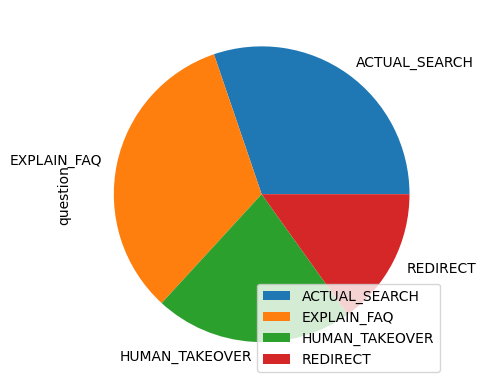

In [56]:
relevant.groupby('action').count().plot.pie(y="question")

In [54]:
len(relevant)

258

In [57]:
relevant.groupby('action').count()

,question,response,embedding
action,,,
ACTUAL_SEARCH,78,78,78
EXPLAIN_FAQ,85,85,85
HUMAN_TAKEOVER,56,56,56
REDIRECT,39,39,39
